In [1]:
print("My Drone Delivery Project has started!")

My Drone Delivery Project has started!


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import zipfile

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
parameters = pd.read_csv("../Dataset/parameters.csv")

print("Dataset loaded successfully!")
print(parameters.head())

Dataset loaded successfully!
   flight  speed  payload altitude        date local_time route
0       1    4.0      0.0       25  2019-04-07      10:13    R5
1       2    4.0      0.0       50  2019-04-07      10:23    R5
2       3    6.0      0.0       25  2019-04-07      10:33    R5
3       4    8.0      0.0       25  2019-04-07      10:48    R5
4       5    4.0      0.0       25  2019-04-07      11:05    R2


In [4]:
print("Number of flights:", len(parameters))
print("\nDataset columns:")
print(parameters.columns.tolist())

print("\nDataset information:")
parameters.info()

Number of flights: 209

Dataset columns:
['flight', 'speed', 'payload', 'altitude', 'date', 'local_time', 'route']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 209 entries, 0 to 208
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   flight      209 non-null    int64  
 1   speed       209 non-null    float64
 2   payload     209 non-null    float64
 3   altitude    209 non-null    str    
 4   date        209 non-null    str    
 5   local_time  209 non-null    str    
 6   route       209 non-null    str    
dtypes: float64(2), int64(1), str(4)
memory usage: 11.6 KB


In [5]:
import zipfile
import os

zip_path = "../Dataset/flights.zip"
extract_path = "../Dataset"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Flight data extracted successfully!")

Flight data extracted successfully!


In [6]:
flight_folder = "../Dataset/flights"

flight_files = [
    file for file in os.listdir(flight_folder)
    if file.endswith(".csv")
]

print("Number of flight files:", len(flight_files))
print("First five files:", flight_files[:5])

Number of flight files: 209
First five files: ['1.csv', '10.csv', '100.csv', '101.csv', '102.csv']


In [7]:
flight1 = pd.read_csv("../Dataset/flights/1.csv")

print(flight1.head())

print("\nColumns in the flight dataset:")
print(flight1.columns.tolist())

   time  wind_speed  wind_angle  battery_voltage  battery_current  position_x  \
0   0.0         0.1        12.0        24.222174         0.087470  -79.782396   
1   0.2         0.1         3.0        24.227180         0.095421  -79.782396   
2   0.3         0.1       352.0        24.225929         0.095421  -79.782396   
3   0.5         0.1       354.0        24.224678         0.095421  -79.782396   
4   0.6         0.1       359.0        24.210905         0.079518  -79.782396   

   position_y  position_z  orientation_x  orientation_y  ...  orientation_w  \
0   40.458047  269.332402       0.001772       0.005610  ...       0.966784   
1   40.458047  269.332056       0.001768       0.005607  ...       0.966783   
2   40.458047  269.333081       0.001768       0.005607  ...       0.966783   
3   40.458047  269.334648       0.001775       0.005614  ...       0.966785   
4   40.458047  269.336178       0.001775       0.005614  ...       0.966785   

   velocity_x  velocity_y  velocity_z 

In [8]:
print("Battery voltage:")
print(flight1["battery_voltage"].describe())

print("\nBattery current:")
print(flight1["battery_current"].describe())

Battery voltage:
count    1339.000000
mean       22.070134
std         0.772592
min        21.228519
25%        21.629802
50%        21.788187
75%        22.022946
max        24.229685
Name: battery_voltage, dtype: float64

Battery current:
count    1339.000000
mean       17.930395
std         8.209225
min         0.055662
25%        19.243294
50%        20.889311
75%        22.284846
max        33.508774
Name: battery_current, dtype: float64


In [10]:
# Calculate instantaneous power
flight1["power_w"] = (
    flight1["battery_voltage"] * flight1["battery_current"]
)

# Calculate average power
average_power = flight1["power_w"].mean()

# Calculate energy consumed in watt-hours
energy_wh = np.trapezoid(
    flight1["power_w"],
    flight1["time"]
) / 3600

# Calculate flight duration
duration = flight1["time"].max() - flight1["time"].min()

print("Flight 1 Results")
print("-------------------------")
print("Average power:", round(average_power, 2), "Watts")
print("Energy consumed:", round(energy_wh, 3), "Wh")
print("Flight duration:", round(duration, 2), "seconds")

Flight 1 Results
-------------------------
Average power: 390.05 Watts
Energy consumed: 21.766 Wh
Flight duration: 200.7 seconds


In [11]:
import os
from pathlib import Path

flight_folder = "../Dataset/flights"

results = []

for file in os.listdir(flight_folder):

    if file.endswith(".csv"):

        # Get flight ID from filename
        flight_id = int(Path(file).stem)

        # Load flight measurements
        data = pd.read_csv(os.path.join(flight_folder, file))

        # Sort measurements by time
        data = data.sort_values("time")

        # Calculate power
        power = data["battery_voltage"] * data["battery_current"]

        # Calculate energy in Wh
        energy = np.trapezoid(
            power,
            data["time"]
        ) / 3600

        # Calculate duration
        duration = data["time"].max() - data["time"].min()

        # Save results
        results.append({
            "flight": flight_id,
            "average_power_w": power.mean(),
            "energy_consumed_wh": energy,
            "duration_seconds": duration
        })

# Create results table
energy_results = pd.DataFrame(results)

# Sort by flight number
energy_results = energy_results.sort_values("flight")

print("Energy calculation completed!")
print("Total flights:", len(energy_results))

energy_results.head(10)

Energy calculation completed!
Total flights: 209


,flight,average_power_w,energy_consumed_wh,duration_seconds
0,1,390.047110,21.765760,200.70
103,2,336.631861,25.374148,271.20
178,3,341.261039,17.090203,180.10
179,4,309.511243,14.701160,171.00
180,5,316.418567,19.048959,217.00
182,6,354.025597,20.113325,204.49
185,7,430.751455,21.523161,179.61
190,8,337.836651,21.927314,233.50
1,10,430.613110,16.546300,138.09
20,12,401.626202,12.991369,116.21


In [12]:
# Clean up the row index
energy_results = energy_results.reset_index(drop=True)

# Combine both datasets using flight number
final_dataset = pd.merge(
    parameters,
    energy_results,
    on="flight",
    how="inner",
    validate="one_to_one"
)

print("Datasets combined successfully!")
print("Total flights:", len(final_dataset))

print("\nCombined dataset:")
display(final_dataset.head(10))

Datasets combined successfully!
Total flights: 209

Combined dataset:


,flight,speed,payload,altitude,date,local_time,route,average_power_w,energy_consumed_wh,duration_seconds
0,1,4.0,0.0,25,2019-04-07,10:13,R5,390.047110,21.765760,200.70
1,2,4.0,0.0,50,2019-04-07,10:23,R5,336.631861,25.374148,271.20
2,3,6.0,0.0,25,2019-04-07,10:33,R5,341.261039,17.090203,180.10
3,4,8.0,0.0,25,2019-04-07,10:48,R5,309.511243,14.701160,171.00
4,5,4.0,0.0,25,2019-04-07,11:05,R2,316.418567,19.048959,217.00
5,6,4.0,0.0,25,2019-04-07,11:18,R3,354.025597,20.113325,204.49
6,7,4.0,0.0,25,2019-05-06,15:43,R4,430.751455,21.523161,179.61
7,8,4.0,0.0,25,2019-05-06,15:56,R1,337.836651,21.927314,233.50
8,10,6.0,0.0,25,2019-05-06,16:08,R1,430.613110,16.546300,138.09
9,12,10.0,0.0,25,2019-05-06,16:19,R1,401.626202,12.991369,116.21


In [13]:
print("Dataset shape:", final_dataset.shape)

print("\nTotal flights:", len(final_dataset))

print("\nMissing values:")
print(final_dataset.isnull().sum())

print("\nData types:")
print(final_dataset.dtypes)

Dataset shape: (209, 10)

Total flights: 209

Missing values:
flight                0
speed                 0
payload               0
altitude              0
date                  0
local_time            0
route                 0
average_power_w       0
energy_consumed_wh    0
duration_seconds      0
dtype: int64

Data types:
flight                  int64
speed                 float64
payload               float64
altitude                  str
date                      str
local_time                str
route                     str
average_power_w       float64
energy_consumed_wh    float64
duration_seconds      float64
dtype: object


In [14]:
print("Unique altitude values:")
print(final_dataset["altitude"].unique())

print("\nAltitude value counts:")
print(final_dataset["altitude"].value_counts())

print("\nPayload values:")
print(final_dataset["payload"].unique())

print("\nSpeed values:")
print(final_dataset["speed"].unique())

Unique altitude values:
<StringArray>
['25', '50', '75', '100', '0', '3', '25-50-100-25']
Length: 7, dtype: str

Altitude value counts:
altitude
25              54
50              48
75              47
100             45
0                9
3                4
25-50-100-25     2
Name: count, dtype: int64

Payload values:
[  0. 250. 750. 500.]

Speed values:
[ 4.  6.  8. 10. 12.  0.]


In [15]:
# Preserve the original altitude column
final_dataset["altitude_original"] = final_dataset["altitude"]

# Convert numeric altitude values
final_dataset["altitude_numeric"] = pd.to_numeric(
    final_dataset["altitude"],
    errors="coerce"
)

# Identify values that could not be converted
print("Non-numeric altitude records:")

print(
    final_dataset[
        final_dataset["altitude_numeric"].isna()
    ][["flight", "altitude_original"]]
)

print("\nNumeric altitude summary:")
print(final_dataset["altitude_numeric"].describe())

Non-numeric altitude records:
     flight altitude_original
207     278      25-50-100-25
208     279      25-50-100-25

Numeric altitude summary:
count    207.000000
mean      56.942029
std       30.923120
min        0.000000
25%       25.000000
50%       50.000000
75%       75.000000
max      100.000000
Name: altitude_numeric, dtype: float64


In [16]:
payload_analysis = (
    final_dataset
    .groupby("payload")
    .agg(
        number_of_flights=("flight", "count"),
        average_energy_wh=("energy_consumed_wh", "mean"),
        average_power_w=("average_power_w", "mean"),
        average_duration_seconds=("duration_seconds", "mean")
    )
    .round(2)
)

print(payload_analysis)

         number_of_flights  average_energy_wh  average_power_w  \
payload                                                          
0.0                     80              16.94           327.58   
250.0                   62              21.43           412.88   
500.0                   66              23.08           437.48   
750.0                    1              25.84           381.97   

         average_duration_seconds  
payload                            
0.0                        178.95  
250.0                      188.91  
500.0                      188.57  
750.0                      243.30  


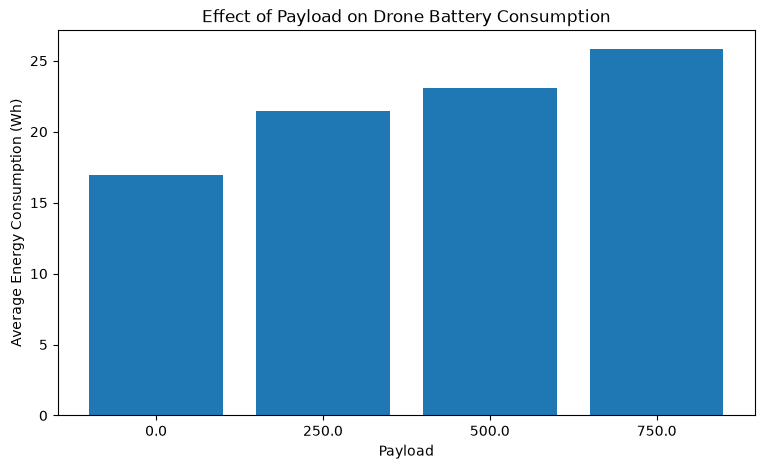

In [17]:
plt.figure(figsize=(9, 5))

plt.bar(
    payload_analysis.index.astype(str),
    payload_analysis["average_energy_wh"]
)

plt.xlabel("Payload")
plt.ylabel("Average Energy Consumption (Wh)")
plt.title("Effect of Payload on Drone Battery Consumption")

plt.show()

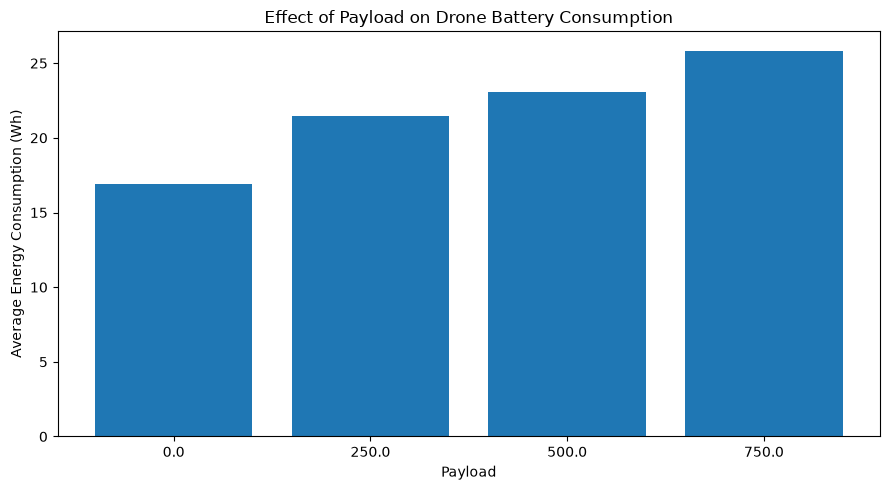

In [18]:
plt.figure(figsize=(9, 5))

plt.bar(
    payload_analysis.index.astype(str),
    payload_analysis["average_energy_wh"]
)

plt.xlabel("Payload")
plt.ylabel("Average Energy Consumption (Wh)")
plt.title("Effect of Payload on Drone Battery Consumption")

plt.tight_layout()

plt.savefig(
    "../Results/payload_energy_graph.png",
    dpi=300
)

plt.show()

In [19]:
plt.savefig(
    "../Results/payload_energy_graph.png",
    dpi=300,
    bbox_inches="tight"
)

<Figure size 640x480 with 0 Axes>

OSError: [Errno 22] Invalid argument: '../Results/payload_energy_graph.png'

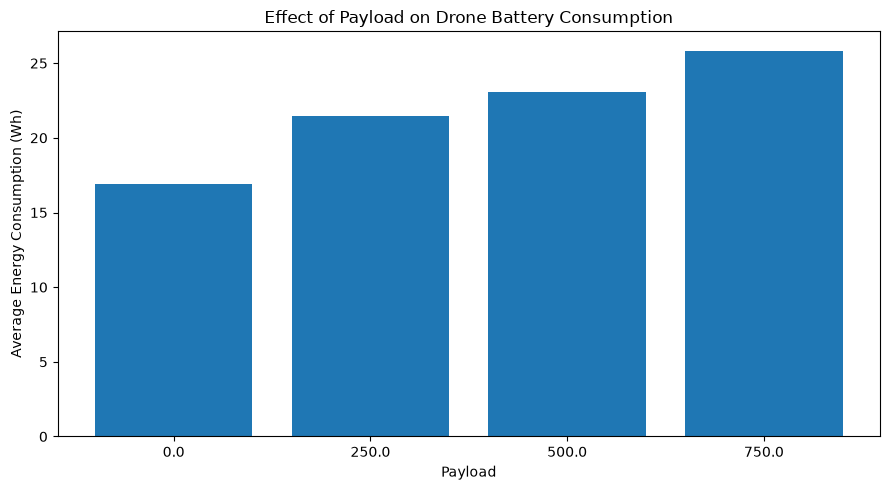

In [20]:
plt.figure(figsize=(9, 5))

plt.bar(
    payload_analysis.index.astype(str),
    payload_analysis["average_energy_wh"]
)

plt.xlabel("Payload")
plt.ylabel("Average Energy Consumption (Wh)")
plt.title("Effect of Payload on Drone Battery Consumption")

plt.tight_layout()

# Save the graph BEFORE displaying it
plt.savefig(
    "../Results/payload_energy_graph.png",
    dpi=300,
    bbox_inches="tight"
)

# Display the graph
plt.show()

print("Graph saved successfully!")

In [21]:
import os
from pathlib import Path

print("Current notebook location:")
print(os.getcwd())

print("\nDoes the Results folder exist?")
print(Path("../Results").exists())

Current notebook location:
C:\Users\USER\Desktop\Drone Delivery Project\Notebooks

Does the Results folder exist?
True


Graph saved at: C:\Users\USER\Desktop\Drone Delivery Project\Results\payload_energy_graph.png
File exists: True
File size: 72647 bytes


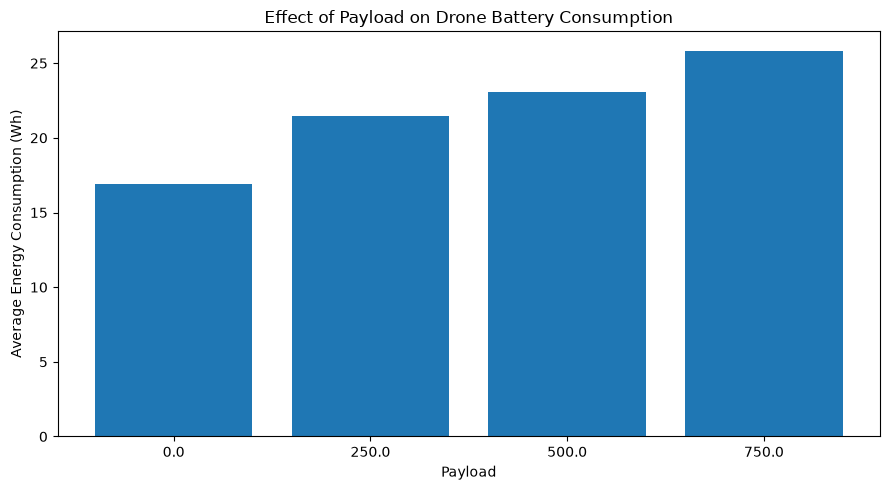

In [22]:
from pathlib import Path

# Create the Results folder if necessary
results_folder = Path("../Results")
results_folder.mkdir(parents=True, exist_ok=True)

# Create the graph
fig, ax = plt.subplots(figsize=(9, 5))

ax.bar(
    payload_analysis.index.astype(str),
    payload_analysis["average_energy_wh"]
)

ax.set_xlabel("Payload")
ax.set_ylabel("Average Energy Consumption (Wh)")
ax.set_title("Effect of Payload on Drone Battery Consumption")

fig.tight_layout()

# Save the graph
save_path = results_folder / "payload_energy_graph.png"

fig.savefig(save_path, dpi=300, bbox_inches="tight")

print("Graph saved at:", save_path.resolve())
print("File exists:", save_path.exists())
print("File size:", save_path.stat().st_size, "bytes")

plt.show()

In [23]:
print(payload_analysis)

         number_of_flights  average_energy_wh  average_power_w  \
payload                                                          
0.0                     80              16.94           327.58   
250.0                   62              21.43           412.88   
500.0                   66              23.08           437.48   
750.0                    1              25.84           381.97   

         average_duration_seconds  
payload                            
0.0                        178.95  
250.0                      188.91  
500.0                      188.57  
750.0                      243.30  


In [24]:
speed_analysis = (
    final_dataset
    .groupby("speed")
    .agg(
        number_of_flights=("flight", "count"),
        average_energy_wh=("energy_consumed_wh", "mean"),
        average_power_w=("average_power_w", "mean"),
        average_duration_seconds=("duration_seconds", "mean")
    )
    .round(2)
)

print(speed_analysis)

       number_of_flights  average_energy_wh  average_power_w  \
speed                                                          
0.0                   13               5.55           143.28   
4.0                   41              26.98           410.70   
6.0                   38              22.14           413.92   
8.0                   36              19.81           398.27   
10.0                  43              18.51           398.54   
12.0                  38              18.53           398.82   

       average_duration_seconds  
speed                            
0.0                      118.63  
4.0                      238.95  
6.0                      192.48  
8.0                      179.30  
10.0                     167.21  
12.0                     168.92  


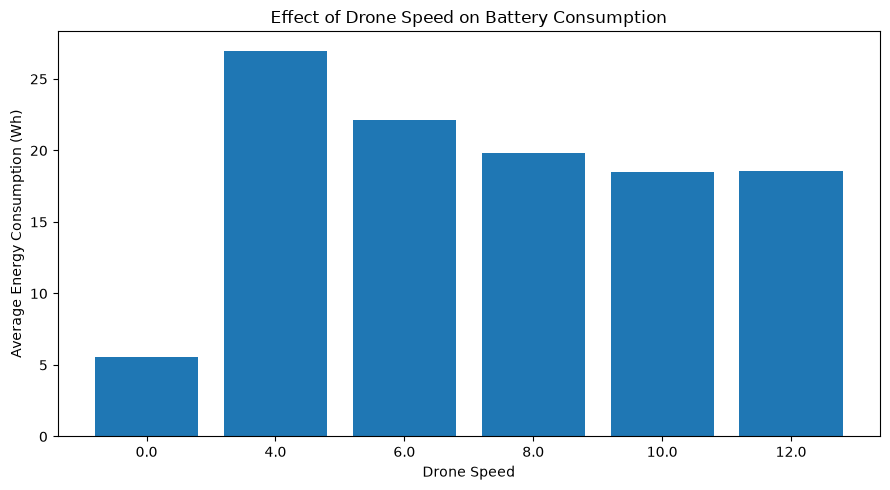

Speed graph saved successfully!


In [25]:
fig, ax = plt.subplots(figsize=(9, 5))

ax.bar(
    speed_analysis.index.astype(str),
    speed_analysis["average_energy_wh"]
)

ax.set_xlabel("Drone Speed")
ax.set_ylabel("Average Energy Consumption (Wh)")
ax.set_title("Effect of Drone Speed on Battery Consumption")

fig.tight_layout()

save_path = results_folder / "speed_energy_graph.png"
fig.savefig(save_path, dpi=300, bbox_inches="tight")

plt.show()

print("Speed graph saved successfully!")

In [26]:
wind_results = []

for file in os.listdir(flight_folder):
    if file.endswith(".csv"):
        flight_id = int(Path(file).stem)

        data = pd.read_csv(os.path.join(flight_folder, file))

        wind_results.append({
            "flight": flight_id,
            "average_wind_speed": data["wind_speed"].mean(),
            "maximum_wind_speed": data["wind_speed"].max()
        })

wind_dataset = pd.DataFrame(wind_results)

final_dataset = pd.merge(
    final_dataset,
    wind_dataset,
    on="flight",
    how="left",
    validate="one_to_one"
)

print(final_dataset[[
    "flight",
    "average_wind_speed",
    "maximum_wind_speed",
    "energy_consumed_wh"
]].head(10))

   flight  average_wind_speed  maximum_wind_speed  energy_consumed_wh
0       1            3.898058                 7.1           21.765760
1       2            3.522941                 9.1           25.374148
2       3            4.581182                11.0           17.090203
3       4            4.596319                11.9           14.701160
4       5            3.333910                 8.3           19.048959
5       6            4.027639                 7.8           20.113325
6       7            4.884712                 7.9           21.523161
7       8            2.914185                 7.8           21.927314
8      10            5.111714                10.5           16.546300
9      12            5.998581                14.8           12.991369


In [27]:
wind_correlation = final_dataset[
    ["average_wind_speed", "maximum_wind_speed",
     "energy_consumed_wh"]
].corr()

print(wind_correlation)

                    average_wind_speed  maximum_wind_speed  energy_consumed_wh
average_wind_speed            1.000000            0.851979            0.389751
maximum_wind_speed            0.851979            1.000000            0.202387
energy_consumed_wh            0.389751            0.202387            1.000000


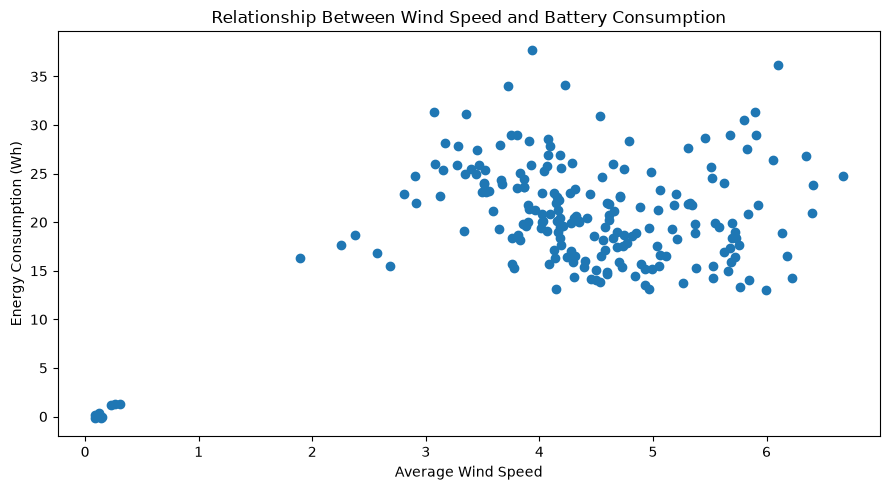

Wind graph saved successfully!


In [28]:
fig, ax = plt.subplots(figsize=(9, 5))

ax.scatter(
    final_dataset["average_wind_speed"],
    final_dataset["energy_consumed_wh"]
)

ax.set_xlabel("Average Wind Speed")
ax.set_ylabel("Energy Consumption (Wh)")
ax.set_title("Relationship Between Wind Speed and Battery Consumption")

fig.tight_layout()

save_path = results_folder / "wind_energy_graph.png"
fig.savefig(save_path, dpi=300, bbox_inches="tight")

plt.show()

print("Wind graph saved successfully!")

In [29]:
important_columns = [
    "speed",
    "payload",
    "altitude_numeric",
    "average_wind_speed",
    "maximum_wind_speed",
    "energy_consumed_wh"
]

correlation_matrix = final_dataset[important_columns].corr()

print(correlation_matrix.round(3))

                    speed  payload  altitude_numeric  average_wind_speed  \
speed               1.000    0.158             0.286               0.600   
payload             0.158    1.000             0.120               0.164   
altitude_numeric    0.286    0.120             1.000               0.354   
average_wind_speed  0.600    0.164             0.354               1.000   
maximum_wind_speed  0.879    0.168             0.394               0.852   
energy_consumed_wh -0.029    0.412             0.666               0.390   

                    maximum_wind_speed  energy_consumed_wh  
speed                            0.879              -0.029  
payload                          0.168               0.412  
altitude_numeric                 0.394               0.666  
average_wind_speed               0.852               0.390  
maximum_wind_speed               1.000               0.202  
energy_consumed_wh               0.202               1.000  


In [30]:
print("Dataset shape:")
print(final_dataset.shape)

print("\nMissing values:")
print(final_dataset.isnull().sum())

print("\nDataset information:")
final_dataset.info()

Dataset shape:
(209, 14)

Missing values:
flight                0
speed                 0
payload               0
altitude              0
date                  0
local_time            0
route                 0
average_power_w       0
energy_consumed_wh    0
duration_seconds      0
altitude_original     0
altitude_numeric      2
average_wind_speed    0
maximum_wind_speed    0
dtype: int64

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 209 entries, 0 to 208
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   flight              209 non-null    int64  
 1   speed               209 non-null    float64
 2   payload             209 non-null    float64
 3   altitude            209 non-null    str    
 4   date                209 non-null    str    
 5   local_time          209 non-null    str    
 6   route               209 non-null    str    
 7   average_power_w     209 non-null    float64
 8 

In [31]:
final_dataset["altitude_feature"] = (
    final_dataset["altitude_numeric"].fillna(50)
)

print(final_dataset[[
    "flight",
    "altitude_original",
    "altitude_feature"
]].tail(10))

     flight altitude_original  altitude_feature
199     268                25              25.0
200     269                25              25.0
201     270                75              75.0
202     271                25              25.0
203     272                50              50.0
204     275                25              25.0
205     276                25              25.0
206     277                25              25.0
207     278      25-50-100-25              50.0
208     279      25-50-100-25              50.0


In [32]:
print("Missing values in altitude_feature:")
print(final_dataset["altitude_feature"].isnull().sum())

print("\nFinal dataset shape:")
print(final_dataset.shape)

Missing values in altitude_feature:
0

Final dataset shape:
(209, 15)


In [33]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

print("Machine learning libraries imported successfully!")

Machine learning libraries imported successfully!


In [34]:
features = [
    "speed",
    "payload",
    "altitude_feature",
    "average_wind_speed"
]

X = final_dataset[features]

y = final_dataset["energy_consumed_wh"]

print("Input features:")
print(X.head())

print("\nTarget values:")
print(y.head())

Input features:
   speed  payload  altitude_feature  average_wind_speed
0    4.0      0.0              25.0            3.898058
1    4.0      0.0              50.0            3.522941
2    6.0      0.0              25.0            4.581182
3    8.0      0.0              25.0            4.596319
4    4.0      0.0              25.0            3.333910

Target values:
0    21.765760
1    25.374148
2    17.090203
3    14.701160
4    19.048959
Name: energy_consumed_wh, dtype: float64


In [35]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 167
Testing records: 42


In [36]:
linear_model = LinearRegression()

linear_model.fit(X_train, y_train)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


In [37]:
y_pred = linear_model.predict(X_test)

print("Actual energy consumption:")
print(y_test.head(10).values)

print("\nPredicted energy consumption:")
print(y_pred[:10])

Actual energy consumption:
[19.8977875  15.06150433 13.0876319  16.65643339 13.71868993  1.23781792
 28.97661234 19.60685099 12.99136918 18.63582502]

Predicted energy consumption:
[21.91709004 15.64371699 11.08905866 20.74235897 16.52035004  8.39126586
 28.68781351 19.20825245 15.42566691 16.37537129]


In [38]:
mae = mean_absolute_error(y_test, y_pred)

rmse = np.sqrt(mean_squared_error(y_test, y_pred))

r2 = r2_score(y_test, y_pred)

print("Linear Regression Model Performance")
print("-----------------------------------")
print("MAE:", round(mae, 3), "Wh")
print("RMSE:", round(rmse, 3), "Wh")
print("R2 Score:", round(r2, 3))

Linear Regression Model Performance
-----------------------------------
MAE: 2.252 Wh
RMSE: 2.79 Wh
R2 Score: 0.725


In [39]:
from sklearn.ensemble import RandomForestRegressor

print("Random Forest imported successfully!")

Random Forest imported successfully!


In [40]:
rf_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    max_depth=5
)

rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [41]:
rf_pred = rf_model.predict(X_test)

rf_mae = mean_absolute_error(y_test, rf_pred)

rf_rmse = np.sqrt(mean_squared_error(y_test, rf_pred))

rf_r2 = r2_score(y_test, rf_pred)

print("Random Forest Model Performance")
print("--------------------------------")
print("MAE:", round(rf_mae, 3), "Wh")
print("RMSE:", round(rf_rmse, 3), "Wh")
print("R2 Score:", round(rf_r2, 3))

Random Forest Model Performance
--------------------------------
MAE: 1.176 Wh
RMSE: 1.422 Wh
R2 Score: 0.929


In [42]:
from sklearn.model_selection import KFold, cross_val_score

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Random Forest cross-validation
rf_mae_scores = -cross_val_score(
    rf_model,
    X,
    y,
    cv=cv,
    scoring="neg_mean_absolute_error"
)

rf_r2_scores = cross_val_score(
    rf_model,
    X,
    y,
    cv=cv,
    scoring="r2"
)

print("Random Forest - 5 Fold Cross Validation")
print("---------------------------------------")
print("MAE scores:", rf_mae_scores.round(3))
print("Average MAE:", round(rf_mae_scores.mean(), 3))
print("MAE standard deviation:", round(rf_mae_scores.std(), 3))

print("\nR2 scores:", rf_r2_scores.round(3))
print("Average R2:", round(rf_r2_scores.mean(), 3))
print("R2 standard deviation:", round(rf_r2_scores.std(), 3))

Random Forest - 5 Fold Cross Validation
---------------------------------------
MAE scores: [1.198 1.377 1.307 1.149 1.162]
Average MAE: 1.239
MAE standard deviation: 0.089

R2 scores: [0.925 0.877 0.881 0.932 0.959]
Average R2: 0.915
R2 standard deviation: 0.031


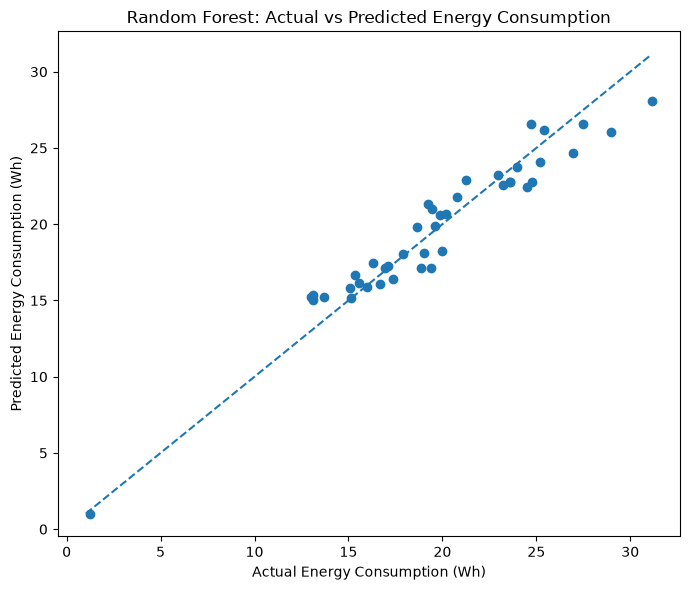

In [43]:
fig, ax = plt.subplots(figsize=(7, 6))

ax.scatter(y_test, rf_pred)

# Perfect prediction reference line
lims = [
    min(y_test.min(), rf_pred.min()),
    max(y_test.max(), rf_pred.max())
]

ax.plot(lims, lims, "--")

ax.set_xlabel("Actual Energy Consumption (Wh)")
ax.set_ylabel("Predicted Energy Consumption (Wh)")
ax.set_title("Random Forest: Actual vs Predicted Energy Consumption")

fig.tight_layout()

fig.savefig(
    results_folder / "rf_actual_vs_predicted.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [44]:
importance = pd.Series(
    rf_model.feature_importances_,
    index=features
).sort_values(ascending=False)

print("Random Forest Feature Importance")
print("--------------------------------")
print(importance.round(4))

Random Forest Feature Importance
--------------------------------
altitude_feature      0.4492
average_wind_speed    0.2433
speed                 0.2414
payload               0.0661
dtype: float64


In [45]:
from sklearn.inspection import permutation_importance

perm_result = permutation_importance(
    rf_model,
    X_test,
    y_test,
    n_repeats=30,
    random_state=42,
    scoring="neg_mean_absolute_error"
)

perm_importance = pd.Series(
    perm_result.importances_mean,
    index=features
).sort_values(ascending=False)

print("Permutation Feature Importance")
print("--------------------------------")
print(perm_importance.round(4))

Permutation Feature Importance
--------------------------------
altitude_feature      2.8710
speed                 1.8019
payload               0.7321
average_wind_speed    0.4254
dtype: float64


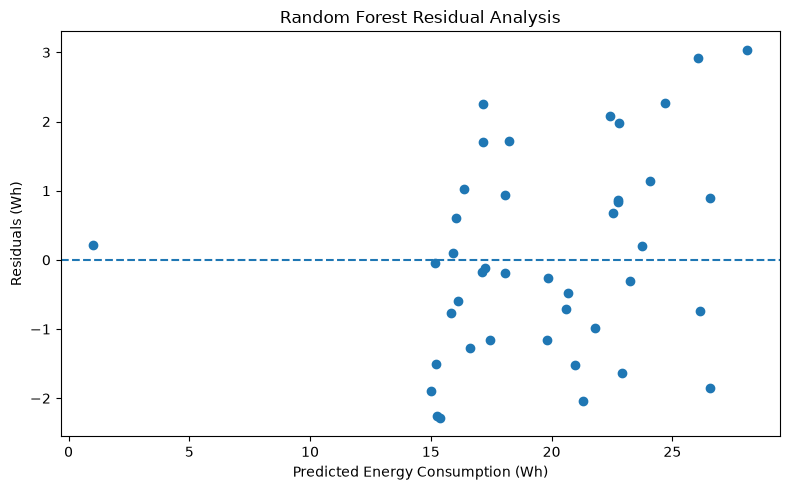

In [46]:
residuals = y_test - rf_pred

plt.figure(figsize=(8, 5))

plt.scatter(rf_pred, residuals)
plt.axhline(y=0, linestyle="--")

plt.xlabel("Predicted Energy Consumption (Wh)")
plt.ylabel("Residuals (Wh)")
plt.title("Random Forest Residual Analysis")

plt.tight_layout()

plt.savefig(
    results_folder / "rf_residual_plot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [47]:
# Linear Regression cross-validation

lr_mae_scores = -cross_val_score(
    linear_model,
    X,
    y,
    cv=cv,
    scoring="neg_mean_absolute_error"
)

lr_r2_scores = cross_val_score(
    linear_model,
    X,
    y,
    cv=cv,
    scoring="r2"
)

print("Linear Regression - 5 Fold Cross Validation")
print("--------------------------------------------")
print("Average MAE:", round(lr_mae_scores.mean(), 3))
print("Average R2:", round(lr_r2_scores.mean(), 3))

Linear Regression - 5 Fold Cross Validation
--------------------------------------------
Average MAE: 2.436
Average R2: 0.718


In [48]:
final_dataset["battery_consumption_percentage"] = (
    final_dataset["energy_consumed_wh"] / 99.9
) * 100

print(
    final_dataset[
        ["flight", "energy_consumed_wh",
         "battery_consumption_percentage"]
    ].head(10).round(2)
)

   flight  energy_consumed_wh  battery_consumption_percentage
0       1               21.77                           21.79
1       2               25.37                           25.40
2       3               17.09                           17.11
3       4               14.70                           14.72
4       5               19.05                           19.07
5       6               20.11                           20.13
6       7               21.52                           21.54
7       8               21.93                           21.95
8      10               16.55                           16.56
9      12               12.99                           13.00


In [49]:
final_dataset["remaining_energy_wh"] = (
    99.9 - final_dataset["energy_consumed_wh"]
)

print(
    final_dataset[
        ["flight", "energy_consumed_wh",
         "remaining_energy_wh"]
    ].head(10).round(2)
)

   flight  energy_consumed_wh  remaining_energy_wh
0       1               21.77                78.13
1       2               25.37                74.53
2       3               17.09                82.81
3       4               14.70                85.20
4       5               19.05                80.85
5       6               20.11                79.79
6       7               21.52                78.38
7       8               21.93                77.97
8      10               16.55                83.35
9      12               12.99                86.91


In [50]:
print("Average energy consumed:",
      round(final_dataset["energy_consumed_wh"].mean(), 2), "Wh")

print("Average remaining energy:",
      round(final_dataset["remaining_energy_wh"].mean(), 2), "Wh")

print("Minimum remaining energy:",
      round(final_dataset["remaining_energy_wh"].min(), 2), "Wh")

print("Maximum remaining energy:",
      round(final_dataset["remaining_energy_wh"].max(), 2), "Wh")

Average energy consumed: 20.25 Wh
Average remaining energy: 79.65 Wh
Minimum remaining energy: 62.15 Wh
Maximum remaining energy: 100.06 Wh
